# EcoHome Energy Advisor - Agent Run & Evaluation

In this notebook, you'll run the Energy Advisor agent with various real-world scenarios and see how it helps customers optimize their energy usage.

## Learning Objectives
- Create the agent's instructions
- Run the Energy Advisor with different types of questions
- Evaluate response quality and accuracy
- Measure tool usage effectiveness
- Identify areas for improvement
- Implement evaluation metrics

## Evaluation Criteria
- **Accuracy**: Correct information and calculations
- **Relevance**: Responses address the user's question
- **Completeness**: Comprehensive answers with actionable advice
- **Tool Usage**: Appropriate use of available tools
- **Reasoning**: Clear explanation of recommendations


## 1. Import and Initialize

In [1]:
from datetime import datetime
import json
import os
import re
import time

import pandas as pd
from agent import Agent, data_errors, data_figures, same_figure, grounded_temperatures, temperature_ok

In [2]:
## The agent's instructions
# Structure: who the advisor is, the steps it follows, what it can do (its tools), how to write
# recommendations, and example questions. Rules that matter for correctness are stated as rules
# ("never invent numbers") rather than as style.

ECOHOME_SYSTEM_PROMPT = """
You are the EcoHome Energy Advisor, an assistant for EcoHome customers who have rooftop solar panels,
an electric vehicle (EV), a smart thermostat (HVAC) and household appliances. Your job is to help each
customer lower their electricity cost and environmental impact with specific, data-backed recommendations.

## How you work, step by step
1. Read the question and the context. The context gives the current date and time, tomorrow's date, the
   next seven dates with their weekday names, and the customer's location. Take the exact dates the question
   refers to ("tomorrow", "Wednesday", "this week") from that list; never work out a weekday yourself.
2. Gather the data the question needs, using the tools below. Call each tool with exact arguments:
   dates as YYYY-MM-DD, the customer's location for weather. For tomorrow, request the forecast with
   days=2 and the prices for tomorrow's date. For a day later this week, request enough forecast days to reach it.
   "The last 7 days" means the seven complete days before today: start_date is 7 days ago, end_date is yesterday.
   The forecast starts TODAY: days=7 covers today and the next six days. Quote only the dates in its daily list.
   "Tonight" starts today and runs past midnight: its hours before midnight are today's prices and its hours
   after midnight (00:00-06:00) are tomorrow's, so get both dates' prices. To price tonight's hours with
   calculate_energy_savings, give today's date and list the hours in the order they run: [22, 23, 0, 1, 2, 3, 4, 5].
   Give each forecast day its own condition (sunny, partly cloudy, cloudy, rainy); never call every day sunny.
   Using more of your own solar: set the forecast against the daily kWh of the loads you move (query_energy_usage).
   Never ask the customer for data a tool can return.
3. Analyse: compare hourly prices with forecast solar generation, and the customer's history where relevant.
4. Recommend: give the specific hours, settings or actions, with the numbers that justify them.
5. Quantify: when the customer asks what they would save, use calculate_energy_savings and quote its
   summary sentence, which states each figure with its period (savings_usd is per period,
   annual_savings_usd is per year). Let the tool take the kWh and the prices from the data: leave
   current_usage_kwh and the prices out. For a reduction pass device_type, date and reduction_percent; for a
   time shift pass device_type, date, current_hours and optimized_hours. The tool then uses the device's
   average daily use from the history (per day) and that date's time-of-use rates. Never use
   average_cost_per_kwh from the usage history as today's rate: those past costs were billed on an older
   flat tariff, not the time-of-use prices.
6. Support with best practice: search the knowledge base for relevant tips and cite the source document.

## Data each kind of question must use (your answer is checked for these before it is accepted)
- Suggestions, ways or tips: call search_energy_tips, apply the passages to this household's data, and cite
  the source file name that search returned for each tip you use. Cite only files a search_energy_tips result
  in this conversation returned; never name a file you have not seen. If you did not search, cite nothing.
- Using more of your own solar: call get_weather_forecast for the days asked about AND query_solar_generation
  for the last 7 days, state what the panels actually produced (the total or daily average) and compare it
  with the forecast for each day you recommend.
- Any quantified saving: call get_electricity_prices and calculate_energy_savings, and quote the tool's
  summary sentence. Never state a saving you worked out another way. One call per saving:
  a reduction across the day is {"device_type": "HVAC", "date": <tomorrow>, "reduction_percent": 10} (say what
  you assumed, e.g. a 10% cut from a 2 degree setback); a reduction during the peak only adds
  "current_hours": [16, 17, 18, 19, 20]; a shift is {"device_type": "EV", "date": <tomorrow>,
  "current_hours": [16, 17, 18, 19, 20], "optimized_hours": [0, 1, 2, 3, 4, 5]}. For one appliance name it:
  device_type "dishwasher", "washing machine" or "dryer". Leave current_usage_kwh, optimized_usage_kwh and the
  prices out for EV, HVAC and appliances: the tool reads them from the data and refuses them if passed.
  Pass current_usage_kwh with a recurring period only for a device the history does not record.
  A saving of $0 means the inputs described no change. In a shift, current_hours are the dearer hours the use
  leaves (e.g. the peak) and optimized_hours the cheaper hours it moves to; the tool refuses a shift into dearer hours.
- Payback and return on investment: when a change has an upfront cost (a smart thermostat, a timer, a battery), pass
  upfront_cost_usd and quote payback_years, payback_months and first_year_roi_percent as returned.
- When the customer asks for savings or suggestions, value every suggestion that moves or cuts a device's use with
  calculate_energy_savings and quote its result; never offer to calculate later.
- Cost and solar together: the cheapest grid hours are off-peak; the best solar hours are usually mid-peak. Solar
  covers at most the day's estimated_solar_kwh in its best window; put that much in the solar window and the rest
  in off-peak hours, and never call mid-peak hours the cheapest.
- "Lowest", "highest" and "up to" must be the table's own minimum or maximum (for that period); name the hour with the
  highest rate only if it is that hour. Say how much of the home's daily use (average_daily_kwh from
  query_energy_usage) the solar covers rather than calling it enough.
- A stated amount ("add 40 kWh") is priced as that amount, once, in the hours you recommend: current_usage_kwh=40,
  period "one_time", date and current_hours only. Quote current_cost_usd; there is no saving to report.
- A cut and a shift are separate calculations; never pass reduction_percent with optimized_hours. If a calculation
  returns an error, fix the call as the error says and call it again.
- Describe each saving exactly as the summary sentence does: the kWh, the hours and whether it is a cut across
  the whole day, a cut in certain hours, or a move to cheaper hours. Never put its cost next to a different kWh.
- The cost of a stated amount of energy (e.g. "add 40 kWh"): call calculate_energy_savings with
  current_usage_kwh set to that amount, period "one_time", date, and current_hours and optimized_hours both set
  to the hours you recommend, and quote its current_cost_usd. Never multiply hours by kWh yourself: the hours
  you list must deliver exactly the amount asked for.
- Tips and sources: name a source only as the tip_....txt file a search_energy_tips call returned. If you did
  not search, give general advice without a source.
- Hourly prices: when you quote a rate for an hour, take it from that hour's row in hourly_rates.
- Money: never work out a dollar figure yourself (no multiplying, subtracting or adding). Every cost or saving
  you state comes from calculate_energy_savings, every rate from get_electricity_prices.
- Hour ranges end where their last hour ends: hours 16-20 are "16:00-21:00", hours 0-5 are "00:00-06:00".
  Copy peak_window, off_peak_window and best_solar_window rather than writing those ranges yourself, and name
  exactly the hours a saving was calculated for (its current_window and optimized_window). Each forecast day has
  its own best_solar_window: give every day its own.
- An "Estimated savings" section states a saving or cost from calculate_energy_savings; without one, leave it out.
- Solar and price together: for a move into a day's solar hours, call calculate_energy_savings with location as well;
  it counts that day's forecast solar in those hours as free and prices the rest at grid rates. Compare that with the
  move to off-peak (the cheapest grid power) and recommend the cheaper, or both (the solar window for what the panels
  cover, off-peak for the rest). Recommend exactly the hours you valued.
- Three ways / suggestions from the usage history: under each suggestion, apply a passage search_energy_tips returned
  to that device's usage and cite the file that passage came from.
- Using more of the home's own solar means running loads (and pre-cooling or pre-heating) in the solar hours.
- Answers based on usage history: call query_energy_usage for the dates you describe.

## Your capabilities (tools)
- get_weather_forecast: hourly forecast with solar irradiance and estimated solar generation for this home.
- get_electricity_prices: hourly time-of-use prices for a date, with cheapest and most expensive hours.
- query_energy_usage: the customer's past consumption by day, device type (EV, HVAC, appliance) and hour of day.
- query_solar_generation: the customer's past solar generation by day, hour and weather.
- get_recent_energy_summary: use and generation over the last few hours. For "the last 24 hours", use this
  tool alone and report its figures once.
- search_energy_tips: energy-saving articles (EV charging, HVAC, appliances, solar, storage, seasonal, automation).
- calculate_energy_savings: savings from using less energy and/or shifting the same energy to cheaper hours.
  To value a time shift, keep the kWh the same and give date, current_hours and optimized_hours.

## Rules for recommendations
- Every number you state (price, kWh, cost, saving, temperature) must come from a tool result or from a
  calculation you show from tool results. Never invent figures. If a figure is an estimate, say so.
- Be specific: name the hours (e.g. "00:00-06:00") and the date. A thermostat setting or setback comes only from a
  tip search_energy_tips returned, stated as the tip states it, with its source file.
- For a deadline ("before 7am tomorrow"), the window starts now: tonight's off-peak hours count. When you
  plan charging, state the charger power you assume (e.g. 7.2 kW for a home charger) and never schedule
  more kWh in an hour than that power allows.
- Explain the trade-off between price and solar availability when both matter, and say which you prioritised.
- Mention the data's limits when they matter: forecasts and prices for future dates are estimates; history
  covers only the dates in the database.
- If a tool returns an error, correct the arguments and try once more; if it still fails, say what you could not check.
- Keep the answer short and structured: Recommendation, Why (the data), Estimated savings (when relevant),
  Tips (with sources).
- Call every tool you need first, then write the whole answer in one final message. The customer sees only
  that last message, so never write part of the answer in a message that also calls a tool.
- Stay on energy topics; if the question is outside them, say so briefly.

## Example questions you handle
- "When should I charge my electric car tomorrow to minimize cost and maximize solar power?"
- "What temperature should I set my thermostat on Wednesday afternoon if electricity prices spike?"
- "Suggest three ways I can reduce energy use based on my usage history."
- "How much can I save by running my dishwasher during off-peak hours?"
- "What's the best time to run my pool pump this week based on the weather forecast?"
""".strip()

print(f"System prompt: {len(ECOHOME_SYSTEM_PROMPT.split())} words")

System prompt: 1797 words


In [3]:
ecohome_agent = Agent(
    instructions=ECOHOME_SYSTEM_PROMPT,
)

In [4]:
response = ecohome_agent.invoke(
    question="When should I charge my electric car tomorrow to minimize cost and maximize solar power?",
    context="Location: San Francisco, CA"
)

In [5]:
print(response["messages"][-1].content)

### Recommendation

To minimize cost and maximize solar power for charging your electric car tomorrow, follow this schedule:

1. **Solar Charging**: Charge during the best solar hours from **11:00 to 14:00**. This period is expected to generate approximately 17.24 kWh of solar energy, which can be used to charge your car for free.

2. **Off-Peak Charging**: If additional charging is needed, use the off-peak hours from **00:00 to 06:00**. These hours have the lowest electricity rates, starting at $0.1057 per kWh.

### Why

- **Solar Generation**: The forecast for tomorrow indicates sunny conditions with an estimated solar generation of 37.93 kWh. The best solar window is from 11:00 to 14:00, where you can utilize up to 17.24 kWh of solar energy.
  
- **Electricity Prices**: The off-peak electricity rates are the lowest, with a minimum rate of $0.1057 per kWh during the hours of 00:00-06:00.

### Estimated Savings

Moving 61.63 kWh a day of EV use from 16:00-21:00 to 00:00-06:00 saves $2

In [6]:
print("TOOLS:")
for msg in response["messages"]:
    obj = msg.model_dump()
    if obj.get("tool_call_id"):
        print("-", msg.name)

TOOLS:
- get_weather_forecast
- get_electricity_prices
- calculate_energy_savings


In [7]:
# The example answer went through the same validation as every test below: show its record, so an answer
# that is still wrong after the advisor was sent back is visible here and not only in the state.
print(f"Validation: missing {response.get('missing_required_tools') or 'none'}; "
      f"unresolved {response.get('content_issues') or 'none'}; sent back {response.get('validation_retries', 0)} time(s)")
for added in response.get("completed_by_code", []):
    print(f"Completed by code: {added}")

Validation: missing none; unresolved none; sent back 1 time(s)


## 2. Define Test Cases

In [8]:
# Test cases: at least 10, covering every scenario family the project names.
# Each case lists:
#   expected_tools   - tools the answer cannot be correct without (scored for completeness)
#   acceptable_tools - extra tools that are reasonable to call (not penalised as inappropriate)
#   expected_response - what a good answer contains (used by the response judge)
SCENARIOS = ["EV charging optimization", "Thermostat settings", "Appliance scheduling",
             "Solar power maximization", "Cost savings calculations", "Usage history analysis"]

In [9]:
test_cases = [
    {
        "id": "ev_charging_1",
        "category": "EV charging optimization",
        "question": "When should I charge my electric car tomorrow to minimize cost and maximize solar power?",
        "expected_tools": ["get_weather_forecast", "get_electricity_prices"],
        "acceptable_tools": ["search_energy_tips", "calculate_energy_savings", "query_energy_usage", "query_solar_generation"],
        "expected_response": "The response should contain time recommendation, cost analysis and solar consideration",
    },
    {
        "id": "ev_charging_overnight",
        "category": "EV charging optimization",
        "question": "I need to add 40 kWh to my EV before 7am tomorrow. Which hours should I charge in, and roughly what will it cost?",
        "expected_tools": ["get_electricity_prices"],
        "acceptable_tools": ["get_weather_forecast", "calculate_energy_savings", "search_energy_tips"],
        "expected_response": "Names specific off-peak hours before 07:00, uses the hourly rates for those hours, and estimates the cost of 40 kWh (about 40 x the off-peak rate).",
    },
    {
        "id": "thermostat_price_spike",
        "category": "Thermostat settings",
        "question": "What temperature should I set my thermostat on Wednesday afternoon if electricity prices spike?",
        "expected_tools": ["get_electricity_prices", "get_weather_forecast"],
        "acceptable_tools": ["search_energy_tips", "query_energy_usage", "calculate_energy_savings"],
        "expected_response": "Works out the date of the coming Wednesday, checks that day's afternoon prices and forecast temperature, and recommends a specific setpoint (raised when cooling, lowered when heating) with pre-cooling or pre-heating before the peak.",
    },
    {
        "id": "thermostat_best_practice",
        "category": "Thermostat settings",
        "question": "What thermostat settings save the most energy without making the house uncomfortable?",
        "expected_tools": ["search_energy_tips"],
        "acceptable_tools": ["query_energy_usage", "get_weather_forecast"],
        "expected_response": "Gives concrete setpoints and setbacks (for example 7-10°F for 8 hours a day for about 10% savings), mentions programmable or smart thermostats, and cites the knowledge base.",
    },
    {
        "id": "dishwasher_off_peak_savings",
        "category": "Cost savings calculations",
        "question": "How much can I save by running my dishwasher during off-peak hours?",
        "expected_tools": ["get_electricity_prices", "calculate_energy_savings"],
        "acceptable_tools": ["query_energy_usage", "search_energy_tips"],
        "expected_response": "Uses the peak and off-peak rates, keeps the energy per cycle the same, and states the saving per cycle and per year with the assumption about energy per cycle.",
    },
    {
        "id": "laundry_schedule_tomorrow",
        "category": "Appliance scheduling",
        "question": "When is the best time to run my washing machine and dryer tomorrow?",
        "expected_tools": ["get_electricity_prices"],
        "acceptable_tools": ["get_weather_forecast", "search_energy_tips", "query_energy_usage", "calculate_energy_savings"],
        "expected_response": "Recommends specific hours tomorrow (off-peak or high solar), explains why using prices and solar, and adds a practical tip such as full loads or cold water.",
    },
    {
        "id": "pool_pump_this_week",
        "category": "Appliance scheduling",
        "question": "What's the best time to run my pool pump this week based on the weather forecast?",
        "expected_tools": ["get_weather_forecast"],
        "acceptable_tools": ["get_electricity_prices", "search_energy_tips", "calculate_energy_savings"],
        "expected_response": "Uses a multi-day forecast to pick the sunniest hours or days, and recommends a daily window for the pump.",
    },
    {
        "id": "solar_self_consumption",
        "category": "Solar power maximization",
        "question": "How can I use more of my own solar power this week instead of buying from the grid?",
        "expected_tools": ["get_weather_forecast", "query_solar_generation"],
        "acceptable_tools": ["query_energy_usage", "search_energy_tips", "get_electricity_prices"],
        "expected_response": "Identifies the peak solar hours from the forecast and history, and recommends moving flexible loads (EV, laundry, dishwasher, pool pump) into them.",
    },
    {
        "id": "solar_history_7_days",
        "category": "Solar power maximization",
        "question": "How much energy did my solar panels generate over the last 7 days, and which days were best?",
        "expected_tools": ["query_solar_generation"],
        "acceptable_tools": ["get_recent_energy_summary"],
        "expected_response": "Reports the 7-day total in kWh, names the best days with their generation and weather, using the database figures.",
    },
    {
        "id": "usage_three_reductions",
        "category": "Usage history analysis",
        "question": "Suggest three ways I can reduce energy use based on my usage history.",
        "expected_tools": ["query_energy_usage", "search_energy_tips", "get_electricity_prices", "calculate_energy_savings"],
        "acceptable_tools": ["get_recent_energy_summary", "query_solar_generation"],
        "expected_response": "Gives exactly three suggestions, each tied to a pattern in the usage history (largest devices, peak-hour use), supported by a retrieved tip with its source file cited, and any saving calculated with calculate_energy_savings from the price table.",
    },
    {
        "id": "ev_shift_annual_savings",
        "category": "Cost savings calculations",
        "question": "If I move my EV charging from the evening peak to overnight off-peak hours, how much would I save per year?",
        "expected_tools": ["get_electricity_prices", "calculate_energy_savings"],
        "acceptable_tools": ["query_energy_usage", "search_energy_tips"],
        "expected_response": "Values the shift with calculate_energy_savings for tomorrow's rates, peak hours to off-peak hours, using the EV's average daily use in those hours from the history (the tool reads it), and states the annual saving.",
    },
    {
        "id": "roi_smart_thermostat",
        "category": "Cost savings calculations",
        "question": "A smart thermostat costs $250. If it cuts my HVAC energy use by 10%, how long would it take to pay for itself?",
        "expected_tools": ["get_electricity_prices", "calculate_energy_savings"],
        "acceptable_tools": ["query_energy_usage", "search_energy_tips", "get_weather_forecast"],
        "expected_response": "Calculates a 10% HVAC cut from the usage history and time-of-use rates with calculate_energy_savings, "
                             "passing the $250 as upfront_cost_usd, and states the annual saving, the payback period and the "
                             "return on investment from that calculation.",
    },
    {
        "id": "recent_usage_summary",
        "category": "Usage history analysis",
        "question": "How much energy did I use in the last 24 hours, and what did it cost?",
        "expected_tools": ["get_recent_energy_summary"],
        "acceptable_tools": ["query_energy_usage"],
        "expected_response": "Reports total kWh and cost for the last 24 hours with the breakdown by device, and notes the period the data covers.",
    },
]

if len(test_cases) < 10:
    raise ValueError("You MUST have at least 10 test cases")
missing = set(SCENARIOS) - {t["category"] for t in test_cases}
assert not missing, f"scenarios without a test case: {missing}"
print(f"{len(test_cases)} test cases across {len({t['category'] for t in test_cases})} scenarios")

13 test cases across 6 scenarios


## 3. Run Agent Tests

In [10]:
CONTEXT = "Location: San Francisco, CA"

In [11]:
# Run the agent tests
# For each test case, call the agent and collect the response.
# Each result also logs the agent's decisions for transparency: every model turn (which tools it chose,
# with which arguments, or that it answered), every tool result (and whether it was an error), the time
# taken and the tokens used.

from langchain_core.messages import AIMessage, ToolMessage


def decision_log(messages):
    """One entry per model turn and per tool result, in order."""
    log = []
    for m in messages:
        if isinstance(m, AIMessage):
            if m.tool_calls:
                log.append({"step": "decide", "action": "call_tools",
                            "tools": [{"name": c["name"], "args": c["args"]} for c in m.tool_calls]})
            else:
                log.append({"step": "decide", "action": "answer", "chars": len(m.content or "")})
        elif isinstance(m, ToolMessage):
            text = m.content if isinstance(m.content, str) else json.dumps(m.content)
            log.append({"step": "tool_result", "tool": m.name,
                        "error": m.status == "error" or text.lstrip().startswith('{"error"'),
                        "preview": text[:160]})
    return log


def token_usage(messages):
    total_in = sum((getattr(m, "usage_metadata", None) or {}).get("input_tokens", 0) for m in messages if isinstance(m, AIMessage))
    total_out = sum((getattr(m, "usage_metadata", None) or {}).get("output_tokens", 0) for m in messages if isinstance(m, AIMessage))
    return {"input_tokens": total_in, "output_tokens": total_out}


print("=== Running Agent Tests ===")
test_results = []

for i, test_case in enumerate(test_cases):
    print(f"\nTest {i+1}: {test_case['id']}")
    print(f"Question: {test_case['question']}")
    print("-" * 50)

    started = time.perf_counter()
    try:
        # Call the agent
        response = ecohome_agent.invoke(
            question=test_case['question'],
            context=CONTEXT
        )
        messages = response["messages"]
        final = messages[-1].content if messages else ""

        # Store the result
        result = {
            'test_id': test_case['id'],
            'category': test_case['category'],
            'question': test_case['question'],
            'response': response,
            'final_response': final,
            'tools_called': [c["name"] for m in messages if isinstance(m, AIMessage) for c in m.tool_calls],
            'decisions': decision_log(messages),
            'validation': {"required_tools": response.get("required_tools", []),
                           "missing_required_tools": response.get("missing_required_tools", []),
                           "content_issues": response.get("content_issues", []),
                           "retries": response.get("validation_retries", 0),
                           "completed_by_code": response.get("completed_by_code", [])},
            'model_turns': response.get("steps", 0),
            'seconds': round(time.perf_counter() - started, 1),
            'tokens': token_usage(messages),
            'expected_tools': test_case['expected_tools'],
            'acceptable_tools': test_case.get('acceptable_tools', []),
            'expected_response': test_case['expected_response'],
            'timestamp': datetime.now().isoformat(),
        }
        result['attempts'] = response.get("attempts", 1)
        result['endpoint_errors'] = response.get("endpoint_errors", [])
        if response.get("error"):
            result['error'] = response["error"]
        test_results.append(result)
        print(f"Tools: {result['tools_called']}  ({result['model_turns']} model turns, {result['seconds']} s)")
        for fail in result['endpoint_errors']:   # a failed try is shown even when a later try answered
            print(f"Attempt failed: {fail['type']}: {fail['message'][:160]} (raised in {fail['origin']}; "
                  f"{'retried' if fail['transient'] else 'not retried: an error in this code, not in reaching the model'})")
        v = result['validation']
        print(f"Validation: required {v['required_tools'] or 'none'}; missing {v['missing_required_tools'] or 'none'}; "
              f"unresolved {v['content_issues'] or 'none'}; sent back {v['retries']} time(s)")
        for added in v['completed_by_code']:   # anything code added to the model's answer is shown, not hidden
            print(f"Completed by code: {added}")
        print(final)   # the whole answer: the reviewer reads it here

    except Exception as e:
        print(f"Error: {e}")
        result = {
            'test_id': test_case['id'],
            'category': test_case['category'],
            'question': test_case['question'],
            'response': f"Error: {str(e)}",
            'final_response': "",
            'tools_called': [],
            'decisions': [],
            'validation': {"required_tools": [], "missing_required_tools": [], "content_issues": [], "retries": 0,
                           "completed_by_code": []},
            'model_turns': 0,
            'seconds': round(time.perf_counter() - started, 1),
            'tokens': {"input_tokens": 0, "output_tokens": 0},
            'expected_tools': test_case['expected_tools'],
            'acceptable_tools': test_case.get('acceptable_tools', []),
            'expected_response': test_case['expected_response'],
            'timestamp': datetime.now().isoformat(),
            'error': str(e)
        }
        test_results.append(result)

print(f"\nCompleted {len(test_results)} tests")

=== Running Agent Tests ===

Test 1: ev_charging_1
Question: When should I charge my electric car tomorrow to minimize cost and maximize solar power?
--------------------------------------------------


Tools: ['get_weather_forecast', 'get_electricity_prices', 'calculate_energy_savings', 'calculate_energy_savings']  (5 model turns, 9.8 s)
Validation: required ['get_weather_forecast', 'get_electricity_prices']; missing none; unresolved none; sent back 1 time(s)
### Recommendation
To minimize cost and maximize solar power, charge your electric car on Saturday, November 21, 2026, during the off-peak hours from **00:00 to 06:00**.

### Why
- **Solar Power**: The best solar generation window on Saturday is from 11:00 to 14:00, with an estimated 17.24 kWh available. However, charging during this time would still require some grid power, as the solar output may not cover the entire charging need.
- **Electricity Prices**: The off-peak hours (00:00-06:00) have the lowest rates, with the minimum rate being **$0.1057 per kWh**, compared to mid-peak rates during the day.

### Estimated Savings
Moving 61.63 kWh of EV use from 16:00-21:00 to 00:00-06:00 saves **$2.84 per day** on Saturday, Novembe

Tools: ['get_electricity_prices', 'get_electricity_prices', 'calculate_energy_savings', 'get_weather_forecast']  (6 model turns, 10.8 s)
Validation: required ['get_weather_forecast']; missing none; unresolved none; sent back 2 time(s)
### Recommendation
To charge your EV with an additional 40 kWh before 7am tomorrow, use the off-peak hours from 22:00 tonight to 06:00 tomorrow morning.

### Why
- **Off-Peak Rates**: Charging during these hours takes advantage of the lowest electricity rates available, with the minimum rate being $0.1057 per kWh during the off-peak period.
- **Time Window**: The off-peak window from 22:00 to 06:00 provides ample time to charge your EV efficiently.
- **Weather Forecast**: The forecast for tonight and tomorrow morning is sunny, but since charging is needed overnight, solar generation will not be available during these hours.

### Estimated Cost
Charging 40 kWh during the off-peak hours from 22:00-06:00 will cost approximately $4.33.

Test 3: thermostat_pri

Tools: ['get_weather_forecast', 'get_electricity_prices', 'search_energy_tips']  (2 model turns, 6.7 s)
Validation: required ['get_weather_forecast', 'get_electricity_prices']; missing none; unresolved none; sent back 0 time(s)
### Recommendation
On Wednesday afternoon, if electricity prices spike, set your thermostat to pre-cool your home by a few degrees below your usual setpoint in the early afternoon. Then, allow the temperature to drift up slowly during the peak period (16:00-21:00). During the peak, you can raise the cooling setpoint by 2 to 4 degrees Fahrenheit (about 1 to 2 degrees Celsius) and use ceiling fans to maintain comfort.

### Why
- **Weather Forecast**: Wednesday is expected to be sunny with high temperatures reaching up to 30.6°C (87.1°F) in the afternoon. The best solar window is from 10:00 to 15:00, with an estimated solar generation of 24.79 kWh during these hours.
- **Electricity Prices**: The peak electricity prices on Wednesday are from 16:00 to 21:00, with th

Tools: ['search_energy_tips']  (2 model turns, 5.5 s)
Validation: required none; missing none; unresolved none; sent back 0 time(s)
### Recommendation

To save energy with your thermostat without making your home uncomfortable, consider the following settings:

1. **Setbacks**: Lower the heating setpoint by 7 to 10 degrees Fahrenheit for 8 hours a day, such as when you are at work or asleep. This can save up to 10% a year on heating and cooling costs.
2. **Smart Thermostat**: Use a smart or programmable thermostat to automatically apply these setbacks. This ensures savings without needing to remember to adjust the settings manually.
3. **Optimal Setpoints**: Set your thermostat to 68°F in winter and 78°F in summer for optimal energy savings.

### Why (the data)

- **Setbacks**: The U.S. Department of Energy suggests that turning the thermostat back 7 to 10 degrees Fahrenheit for 8 hours a day can save up to 10% annually on heating and cooling.
- **Smart Thermostat**: Automatically adju

Tools: ['get_electricity_prices', 'query_energy_usage', 'calculate_energy_savings']  (3 model turns, 6.1 s)
Validation: required ['get_electricity_prices', 'calculate_energy_savings']; missing none; unresolved none; sent back 0 time(s)
### Recommendation
Run your dishwasher during off-peak hours, specifically from 00:00 to 06:00.

### Why
- **Current Usage**: Your dishwasher currently uses an average of 1.75 kWh per day during peak hours (16:00-21:00).
- **Electricity Prices**: The average rate during peak hours is $0.2572 per kWh, while during off-peak hours (00:00-06:00), it drops to $0.1128 per kWh.

### Estimated Savings
Moving 1.75 kWh a day of dishwasher use from 16:00-21:00 to 00:00-06:00 saves $0.25 per day ($0.45 now at $0.2572/kWh, $0.20 after at $0.1128/kWh) on Friday 2026-11-20. Over the 7 days from 2026-11-20 to 2026-11-26, a weekday saves $0.24 on average and a weekend day $0.08, which is $72.29 a year.

Test 6: laundry_schedule_tomorrow
Question: When is the best time to

... (4 outputs left out)

Tools: ['query_energy_usage', 'search_energy_tips', 'get_electricity_prices', 'calculate_energy_savings', 'calculate_energy_savings', 'calculate_energy_savings']  (6 model turns, 17.7 s)
Validation: required ['get_electricity_prices', 'calculate_energy_savings', 'query_energy_usage', 'search_energy_tips']; missing none; unresolved none; sent back 2 time(s)
Based on your recent energy usage history and relevant energy-saving tips, here are three ways you can reduce energy use:

### 1. Optimize EV Charging
**Recommendation:** Schedule your EV charging during off-peak hours (00:00-06:00) instead of the evening peak (16:00-21:00).

**Why:** Your EV accounts for a significant portion of your energy consumption (1532.4 kWh over the last 7 days). By shifting charging to off-peak hours, you can reduce costs significantly.

**Estimated Savings:** Moving 61.63 kWh a day of EV use from 16:00-21:00 to 00:00-06:00 saves $2.84 per day on Saturday 2026-11-21, which is $2541.50 a year. [Source: tip_sm

Tools: ['get_electricity_prices', 'get_electricity_prices', 'query_energy_usage', 'calculate_energy_savings']  (3 model turns, 6.1 s)
Validation: required ['get_electricity_prices', 'calculate_energy_savings']; missing none; unresolved none; sent back 0 time(s)
### Recommendation
Move your EV charging from the evening peak hours (16:00-21:00) to the overnight off-peak hours (00:00-06:00).

### Why
- **Current Usage**: Your EV currently uses an average of 61.63 kWh during the peak hours (16:00-21:00).
- **Current Cost**: Charging during these peak hours costs approximately $15.85 per day at an average rate of $0.2572 per kWh.
- **Optimized Cost**: By shifting to off-peak hours (00:00-06:00), the cost drops to about $6.95 per day at an average rate of $0.1128 per kWh.

### Estimated Savings
Moving 61.63 kWh a day of EV use from 16:00-21:00 to 00:00-06:00 saves $8.90 per day ($15.85 now at $0.2572/kWh, $6.95 after at $0.1128/kWh) on Friday 2026-11-20; over the 7 days 2026-11-20 to 2026-11

Tools: ['query_energy_usage', 'get_electricity_prices', 'calculate_energy_savings']  (3 model turns, 6.2 s)
Validation: required ['get_electricity_prices', 'calculate_energy_savings']; missing none; unresolved none; sent back 0 time(s)
### Recommendation

Investing in a smart thermostat that costs $250 and reduces your HVAC energy use by 10% would pay for itself in approximately 0.93 years, or about 11.2 months.

### Why

- **Current HVAC Usage**: Your HVAC system currently uses an average of 46.25 kWh per day.
- **Cost Reduction**: By reducing energy use by 10%, your daily consumption would decrease to 41.62 kWh.
- **Daily Savings**: This reduction saves approximately $0.65 per day on a weekend day like Saturday, November 21, 2026.
- **Annual Savings**: The annual savings would amount to approximately $267.64, based on your usage patterns.

### Estimated Savings

Using 10% less HVAC energy across the whole day (46.25 kWh a day down to 41.62 kWh, same price) saves $0.65 per day ($6.48 

Tools: ['get_recent_energy_summary']  (2 model turns, 2.8 s)
Validation: required none; missing none; unresolved none; sent back 0 time(s)
In the last 24 hours, you used a total of 320.36 kWh of energy, which cost you $37.28. Here's the breakdown by device type:

- **Electric Vehicle (EV):** 236.92 kWh, costing $27.43
- **HVAC:** 49.65 kWh, costing $6.01
- **Appliances:** 33.79 kWh, costing $3.84

Additionally, your solar panels generated 30.52 kWh of energy during this period, with sunny weather recorded.

Completed 13 tests


In [12]:
# test_results holds everything above, including the full message history of each run in 'response'.
# A compact view; the decision log of the first test shows what is recorded for every test.
pd.set_option("display.max_colwidth", 70)
display(pd.DataFrame([{
    "test": r["test_id"], "tools called": ", ".join(r["tools_called"]), "turns": r["model_turns"],
    "seconds": r["seconds"], "tokens in/out": f"{r['tokens']['input_tokens']}/{r['tokens']['output_tokens']}",
    "error": r.get("error", ""),
} for r in test_results]))
print(json.dumps(test_results[0]["decisions"], indent=1)[:1500])

# Every tool call each test made, with its arguments, and what each savings calculation used: the evidence
# behind each figure in the answers above, so a reader can check them.
for r in test_results:
    print(f"\n[{r['test_id']}]")
    for m in (r["response"]["messages"] if isinstance(r.get("response"), dict) else []):
        for call in getattr(m, "tool_calls", None) or []:
            print(f"  call {call['name']}({json.dumps(call['args'])})")
        if isinstance(m, ToolMessage) and m.name == "calculate_energy_savings":
            try:
                c = json.loads(m.content)
            except (TypeError, ValueError):
                continue
            print(f"    -> {c.get('summary') or c.get('error')}  usage: {c.get('current_usage_kwh')} kWh, {c.get('usage_from')}; "
                  f"prices: {c.get('price_per_kwh')} -> {c.get('optimized_price_per_kwh')}, {c.get('prices_from')}")

,test,tools called,turns,seconds,tokens in/out,error
0,ev_charging_1,"get_weather_forecast, get_electricity_prices, calculate_energy_sav...",5,9.8,50208/690,
1,ev_charging_overnight,"get_electricity_prices, get_electricity_prices, calculate_energy_s...",6,10.8,55062/630,
2,thermostat_price_spike,"get_weather_forecast, get_electricity_prices, search_energy_tips",2,6.7,24540/444,
3,thermostat_best_practice,search_energy_tips,2,5.5,12496/366,
4,dishwasher_off_peak_savings,"get_electricity_prices, query_energy_usage, calculate_energy_savings",3,6.1,22285/369,
5,laundry_schedule_tomorrow,"get_weather_forecast, get_electricity_prices, query_energy_usage, ...",6,17.0,69905/1521,
6,pool_pump_this_week,"get_weather_forecast, query_solar_generation",2,6.5,25091/423,
7,solar_self_consumption,"get_weather_forecast, query_solar_generation, query_energy_usage",5,18.6,88302/2071,
8,solar_history_7_days,query_solar_generation,2,3.7,12250/258,
9,usage_three_reductions,"query_energy_usage, search_energy_tips, get_electricity_prices, ca...",6,17.7,51808/1505,


[
 {
  "step": "decide",
  "action": "call_tools",
  "tools": [
   {
    "name": "get_weather_forecast",
    "args": {
     "location": "San Francisco, CA",
     "days": 2
    }
   },
   {
    "name": "get_electricity_prices",
    "args": {
     "date": "2026-11-21"
    }
   }
  ]
 },
 {
  "step": "tool_result",
  "tool": "get_weather_forecast",
  "error": false,
  "preview": "{\"location\": \"San Francisco, CA\", \"forecast_days\": 2, \"source\": \"simulated\", \"current\": {\"temperature_c\": 11.8, \"condition\": \"sunny\", \"humidity\": 38, \"wind_spee"
 },
 {
  "step": "tool_result",
  "tool": "get_electricity_prices",
  "error": false,
  "preview": "{\"date\": \"2026-11-21\", \"day_of_week\": \"Saturday\", \"pricing_type\": \"time_of_use\", \"currency\": \"USD\", \"unit\": \"per_kWh\", \"source\": \"simulated\", \"hourly_rates\": [{"
 },
 {
  "step": "decide",
  "action": "call_tools",
  "tools": [
   {
    "name": "calculate_energy_savings",
    "args": {
     "device_type": "EV"

## 4. Evaluate Responses

In [13]:
# Evaluation setup.
# Two kinds of check, because they catch different failures:
#  * An LLM judge scores each answer for ACCURACY, RELEVANCE, COMPLETENESS and USEFULNESS (1-5) with feedback.
#    The judge is gpt-4o, the same model as the advisor, and it is shown the tool results, so it can check the
#    answer's figures against the data the advisor actually received. A model can favour answers written like its
#    own, so the code checks below decide everything code can decide, and a data error caps ACCURACY at 2.
#  * Plain code checks what code can decide exactly: which tools were called, and whether each figure in
#    the answer can be found in the tool results.
from typing import Literal
from pydantic import BaseModel
from langchain_openai import ChatOpenAI

JUDGE_MODEL = "gpt-4o"
judge_llm = ChatOpenAI(model=JUDGE_MODEL, temperature=0.0, base_url="https://openai.vocareum.com/v1",
                       api_key=os.getenv("VOCAREUM_API_KEY"), timeout=90, max_retries=2)


class MetricScore(BaseModel):
    score: Literal[1, 2, 3, 4, 5]
    feedback: str


class ResponseJudgement(BaseModel):
    accuracy: MetricScore
    relevance: MetricScore
    completeness: MetricScore
    usefulness: MetricScore
    overall_feedback: str


judge = judge_llm.with_structured_output(ResponseJudgement, method="function_calling")
RESPONSE_METRICS = ["accuracy", "relevance", "completeness", "usefulness"]
TOOL_METRICS = ["tool_appropriateness", "tool_completeness"]

JUDGE_INSTRUCTIONS = """You are grading an energy advisor's answer to a customer. Score each metric from 1 (poor) to 5 (excellent):
- accuracy: are the facts and figures correct and consistent with the tool results shown? Invented or contradicted figures score 1-2.
- relevance: does it answer the question that was asked, for the right dates and devices?
- completeness: does it cover what the expected response describes?
- usefulness: could the customer act on it today (specific hours, settings, amounts)?
The tool results shown to you may be trimmed. The code checks listed below ran on the complete results: a figure
that is not in their "not found" list WAS found in the data, so do not call it invented because you cannot see it.
A figure stated for the wrong period (a daily saving called yearly) is a contradicted figure.
Give one or two sentences of feedback per metric naming what is right or wrong. Then an overall feedback sentence."""


def tool_outputs_from(messages, limit=24000):
    """The tool results the advisor saw, as text for the judge.

    Long results are trimmed, but each tool gets an equal share of the limit, so a long forecast can no longer
    push the price table out of the judge's view (with one cut at the end, the judge once marked correct
    off-peak rates as invented because it never saw them).
    """
    parts = [f"[{m.name}] {m.content if isinstance(m.content, str) else json.dumps(m.content)}"
             for m in messages if isinstance(m, ToolMessage)]
    if not parts:
        return ""
    share = limit // len(parts)
    return "\n".join(p if len(p) <= share else p[:share] + " [... trimmed]" for p in parts)


NUMBER = re.compile(r"\$\s?(-?\d[\d,]*(?:\.\d+)?)|(-?\d[\d,]*(?:\.\d+)?)\s?(?:kWh|kwh|%|°\s?([CF])\b)")


def numbers_in_tools(messages):
    """Every number that appears in any tool result."""
    found = set()
    for m in messages:
        if isinstance(m, ToolMessage):
            text = m.content if isinstance(m.content, str) else json.dumps(m.content)
            found.update(float(x) for x in re.findall(r"-?\d+(?:\.\d+)?", text))
    return found


def check_figures(final_response, messages):
    """Money, kWh and percentage figures in the answer that cannot be found in any tool result.

    A figure counts as found when a tool value matches it to within 1% (or 0.011 for small values).
    A temperature counts as found when it is a temperature a tool gave (a forecast value or a figure in a
    retrieved tip) or a unit conversion of one, the same rule the advisor's validation applies: any number
    elsewhere in the results (a humidity of 78) does not make 78°F found, and 20°C for a tip's 68°F is not invented.
    A figure the advisor calculated (a sum, a product) will not be found: it is reported as
    'not found in tool results', for a person or the judge to check, not as an error.
    """
    tool_values = numbers_in_tools(messages)
    temps = grounded_temperatures(messages)
    figures, unmatched = [], []
    for m in NUMBER.finditer(final_response or ""):
        raw = (m.group(1) or m.group(2)).replace(",", "")
        value = float(raw)
        figures.append(m.group(0).strip())
        if m.group(3):
            found = temperature_ok(raw, m.group(3), temps)
        else:
            found = any(abs(value - v) <= max(0.011, 0.01 * abs(v)) for v in tool_values)
        if not found:
            unmatched.append(m.group(0).strip())
    return {"figures_checked": len(figures), "not_found_in_tool_results": unmatched,
            "found_in_tool_results": [f for f in figures if f not in unmatched]}


MONEY = re.compile(r"\$\s?(\d[\d,]*(?:\.\d+)?)")
YEARLY = re.compile(r"\b(year|yearly|annual|annually|per yr)\b", re.I)
PERIOD = re.compile(r"\b(year|yearly|annual|annually|per yr|day|daily|week|weekly|month|monthly|cycle|charge|load)\b", re.I)
BOUNDARY = re.compile(r"[$\d\n;()]|\.\s")


def check_periods(final_response, messages):
    """Savings figures stated for the wrong period, decided in code.

    For every calculate_energy_savings result whose per-period saving differs from its annual saving, any
    money figure in the answer equal to the per-period saving is examined: if the words right next to it
    (up to the neighbouring figure or the end of the sentence) say "year" or "annual", the answer has called
    a daily or weekly saving yearly. Returns one message per such figure.
    """
    issues = []
    text = final_response or ""
    for m in messages:
        if not (isinstance(m, ToolMessage) and m.name == "calculate_energy_savings"):
            continue
        try:
            r = json.loads(m.content) if isinstance(m.content, str) else m.content
        except (TypeError, ValueError):
            continue
        if not isinstance(r, dict) or "savings_usd" not in r or r.get("period") in ("year", "one_time"):
            continue
        per, annual = r["savings_usd"], r["annual_savings_usd"]
        if abs(per - annual) < 0.011:
            continue
        for fig in MONEY.finditer(text):
            if abs(float(fig.group(1).replace(",", "")) - per) > 0.011:
                continue
            after = BOUNDARY.split(text[fig.end():], maxsplit=1)[0][:60]
            before = BOUNDARY.split(text[:fig.start()][::-1], maxsplit=1)[0][::-1][-60:]
            # the figure's own period is the nearest period word: first one after it, else the last one before it
            nearest = PERIOD.search(after) or (list(PERIOD.finditer(before)) or [None])[-1]
            if nearest is not None and YEARLY.fullmatch(nearest.group(0)):
                issues.append(f"{fig.group(0)} is the saving per {r['period']}, but the answer calls it yearly "
                              f"(the tool's annual figure is ${annual:,.2f})")
    return issues


CITED = re.compile(r"\btip_[A-Za-z0-9_]+\.txt\b")


def check_citations(final_response, messages):
    """Knowledge-base files the answer cites that no search_energy_tips result returned (invented sources)."""
    returned = set()
    for m in messages:
        if isinstance(m, ToolMessage) and m.name == "search_energy_tips":
            try:
                returned |= {t.get("source") for t in json.loads(m.content).get("tips", [])}
            except (TypeError, ValueError, AttributeError):
                continue
    return sorted(set(CITED.findall(final_response or "")) - returned)

In [14]:
def evaluate_response(question, final_response, expected_response, messages=None):
    """Evaluate a single response against expected response.

    Returns a dict with a 1-5 score and feedback for ACCURACY, RELEVANCE, COMPLETENESS and USEFULNESS,
    the same scores on a 0-1 scale, overall feedback, and a figure check against the tool results.
    If the judge cannot be reached, the scores are None (unknown), never a pass.
    """
    messages = messages or []
    figures = check_figures(final_response, messages)
    periods = check_periods(final_response, messages)
    citations = check_citations(final_response, messages)
    # The same data checks the advisor's validation step applies, run again here independently of what the
    # advisor reported about itself: savings computed from usage for the wrong span of time, hourly prices put
    # against the wrong hours, money no tool returned, a day's figure given to another day, hour ranges one hour
    # short or not the hours that were priced, a saving described as a different change, and 'tonight' quoted
    # from another day's prices.
    found_errors = data_errors(messages, final_response or "", question=question)
    result = {"scores": {}, "normalized": {}, "feedback": {}, "overall_feedback": "", "figures": figures,
              "period_errors": periods, "citation_errors": citations, "data_errors": found_errors, "judge_error": None}
    if not (final_response or "").strip():
        result["judge_error"] = "empty response"
        return result
    prompt = (f"{JUDGE_INSTRUCTIONS}\n\nToday: {datetime.now():%Y-%m-%d (%A)}\n\nQuestion:\n{question}\n\n"
              f"Expected response:\n{expected_response}\n\nTool results the advisor received:\n{tool_outputs_from(messages) or '(none)'}\n\n"
              f"Figures in the answer not found in the tool results (may be calculations; check them): "
              f"{figures['not_found_in_tool_results'] or 'none'}\n\nFigures in the answer that code FOUND in the complete tool "
              f"results (do not call these unsupported): {sorted(set(figures['found_in_tool_results'])) or 'none'}"
              f"\n\nSavings or rates that do not match the data they came from (found by code): {found_errors or 'none'}"
              f"\n\nSavings stated for the wrong period (found by code): "
              f"{periods or 'none'}\n\nCited files that no search returned (found by code): {citations or 'none'}"
              f"\n\nAdvisor's answer:\n{final_response}")
    try:
        verdict = judge.invoke(prompt)
    except Exception as e:
        result["judge_error"] = f"{type(e).__name__}: {e}"
        return result
    for metric in RESPONSE_METRICS:
        ms = getattr(verdict, metric)
        result["scores"][metric] = ms.score
        result["normalized"][metric] = round((ms.score - 1) / 4, 2)
        result["feedback"][metric] = ms.feedback
    result["overall_feedback"] = verdict.overall_feedback
    if periods and result["scores"]["accuracy"] > 2:
        # Code decides what code can decide: a saving stated for the wrong period is a wrong figure,
        # whatever the judge thought of the rest. Accuracy is capped at 2/5 and the reason recorded.
        result["scores"]["accuracy"] = 2
        result["normalized"]["accuracy"] = 0.25
        result["feedback"]["accuracy"] += f" [Capped at 2 by the period check: {periods[0]}]"
    if citations and result["scores"]["accuracy"] > 2:
        # An invented source is an invented fact: the same cap, decided in code.
        result["scores"]["accuracy"] = 2
        result["normalized"]["accuracy"] = 0.25
        result["feedback"]["accuracy"] += f" [Capped at 2 by the citation check: {', '.join(citations)} never returned by a search]"
    if found_errors and result["scores"]["accuracy"] > 2:
        # A saving built on a week's usage labelled as a day's, or a rate from the wrong hour, is a wrong figure.
        result["scores"]["accuracy"] = 2
        result["normalized"]["accuracy"] = 0.25
        result["feedback"]["accuracy"] += f" [Capped at 2 by the data check: {found_errors[0]}]"
    return result

In [15]:
DATA_NUMBER = re.compile(r"\d[\d,]*(?:\.\d+)?")


def _data_numbers(text):
    """Decimals, and whole numbers above 31: numbers that identify data rather than hours or days."""
    return {float(r.replace(",", "")) for r in DATA_NUMBER.findall(text or "") if "." in r or float(r.replace(",", "")) > 31}


def _windows_used(texts, answer):
    """True when the answer names at least two of the forecast's per-day best_solar_window ranges, each with its day."""
    hits = 0
    for t in texts:
        try:
            daily = json.loads(t).get("daily", [])
        except (TypeError, ValueError, AttributeError):
            continue
        for x in daily:
            win, wd = x.get("best_solar_window"), str(x.get("day_of_week", ""))
            if win and wd and any(wd in line and win in line.replace(" ", "") for line in answer.replace("**", "").splitlines()):
                hits += 1
    return hits >= 2


def unused_results(messages, tools):
    """Expected tools whose results the final answer does not reflect.

    search_energy_tips counts as used when the answer cites a file it returned; any other tool when the
    answer quotes a figure from its result. A tool can be called and still ignored; this shows it.
    """
    answer = next((m.content for m in reversed(messages) if isinstance(m, AIMessage) and not m.tool_calls), "") or ""
    found, cited, unused = _data_numbers(answer), set(CITED.findall(answer)), []
    for name in tools:
        texts = [m.content if isinstance(m.content, str) else json.dumps(m.content)
                 for m in messages if isinstance(m, ToolMessage) and m.name == name]
        if name == "search_energy_tips":
            sources = set()
            for t in texts:
                try:
                    sources |= {x.get("source") for x in json.loads(t).get("tips", [])}
                except (TypeError, ValueError, AttributeError):
                    pass
            if not cited & sources:
                unused.append(name)
        elif name == "get_weather_forecast" and _windows_used(texts, answer):
            continue   # each day's best_solar_window is forecast data too (a live pool-pump answer listed them, no kWh)
        else:
            # only the figures that describe data (kWh, USD, rates...), not counts or hours: see data_figures in agent.py
            values = set()
            for t in texts:
                try:
                    values |= {v for v in data_figures(json.loads(t)) if v != int(v) or v > 31}
                except (TypeError, ValueError):
                    values |= _data_numbers(t)
            for m in messages:
                if not (isinstance(m, ToolMessage) and m.name == "calculate_energy_savings"):
                    continue
                try:
                    c = json.loads(m.content)
                except (TypeError, ValueError):
                    continue
                # rates the savings calculator looked up count as the price table's data, and usage it read from
                # the history (usage_from "average daily ...") counts as the usage history's data
                if name == "get_electricity_prices" and str(c.get("prices_from", "")).startswith("time-of-use rates"):
                    # its rates, and the costs and savings computed from them, came from the price table
                    values |= {v for v in data_figures(c) if v != int(v) or v > 31} - {c.get("current_usage_kwh"), c.get("optimized_usage_kwh"), c.get("savings_kwh")}
                if name == "query_energy_usage" and str(c.get("usage_from", "")).startswith("average daily"):
                    values |= {c.get("current_usage_kwh"), c.get("optimized_usage_kwh")} - {None}
            # a figure that another tool's result also holds is not evidence for this one (a forecast 22.51 is not
            # the history's 22.52 average); figures must match as printed, to the hundredth
            others = set()
            for m in messages:
                if isinstance(m, ToolMessage) and m.name != name and m.name != "calculate_energy_savings":
                    try:
                        others |= data_figures(json.loads(m.content))
                    except (TypeError, ValueError):
                        pass
            mine = {a for a in found if not any(same_figure(a, o) for o in others - values)}
            if values and not any(same_figure(a, b) for a in mine for b in values):
                unused.append(name)
    return unused


def evaluate_tool_usage(messages, expected_tools, acceptable_tools=None):
    """Evaluate if the right tools were used.

    Tool appropriateness: the share of tool calls that went to a tool the task needed or could reasonably use
        (expected_tools plus acceptable_tools). Calling an unrelated tool lowers it.
    Tool completeness: the share of expected_tools that were called at least once.
    Also reported: tools that errored, repeated identical calls, and feedback naming what was missing or extra.
    required_calls_ok is a pass/fail check kept apart from the scores: every expected tool was called AND
    returned data. A missing data step is a failure on its own, whatever the averages say.
    """
    expected = list(dict.fromkeys(expected_tools or []))
    allowed = set(expected) | set(acceptable_tools or [])
    calls = [(c["name"], json.dumps(c["args"], sort_keys=True)) for m in messages if isinstance(m, AIMessage) for c in (m.tool_calls or [])]
    used = [name for name, _ in calls]
    used_set = set(used)
    errors = sorted({m.name for m in messages if isinstance(m, ToolMessage)
                     and (m.status == "error" or str(m.content).lstrip().startswith('{"error"'))})
    repeated = sorted({name for name, args in calls if calls.count((name, args)) > 1})
    missing = [t for t in expected if t not in used_set]
    unexpected = sorted(used_set - allowed)
    succeeded = {m.name for m in messages if isinstance(m, ToolMessage)
                 and m.status != "error" and not str(m.content).lstrip().startswith('{"error"')}
    failed_only = [t for t in expected if t in used_set and t not in succeeded]   # called, but never returned data
    unused = unused_results(messages, [t for t in expected if t in succeeded])

    if used:
        appropriateness = round(sum(name in allowed for name in used) / len(used), 2)
    else:
        appropriateness = 1.0 if not expected else 0.0   # no call is only appropriate when none was needed
    completeness = round((len(expected) - len(missing)) / len(expected), 2) if expected else 1.0

    feedback = []
    if missing:
        feedback.append(f"Missing required tools: {', '.join(missing)}.")
    if unexpected:
        feedback.append(f"Called tools not relevant to this task: {', '.join(unexpected)}.")
    if failed_only:
        feedback.append(f"Required tools called but never returned data: {', '.join(failed_only)}.")
    if unused:
        feedback.append(f"Results not reflected in the answer: {', '.join(unused)}.")
    if errors:
        feedback.append(f"Tool errors from: {', '.join(errors)}.")
    if repeated:
        feedback.append(f"Repeated identical calls to: {', '.join(repeated)}.")
    if not feedback:
        feedback.append("All required tools were used and every call was relevant.")
    return {"tool_appropriateness": appropriateness, "tool_completeness": completeness, "tools_used": used,
            "missing_tools": missing, "unexpected_tools": unexpected, "tool_errors": errors,
            "failed_required_tools": failed_only, "required_calls_ok": not missing and not failed_only,
            "unused_tools": unused, "data_used_ok": not unused,
            "repeated_calls": repeated, "feedback": " ".join(feedback)}

In [16]:
# Generate a comprehensive evaluation report
# Calculate overall scores and metrics      -> in code (averages, pass counts, timing, tokens)
# Identify strengths and weaknesses         -> written by a model from the evidence, each tied to test ids
# Provide recommendations for improvement   -> written by a model from the evidence, each tied to test ids
# Required-call validation is a separate pass/fail check, never averaged into a score, so a skipped data
# step cannot hide behind good scores elsewhere.
from typing import List

PASS_THRESHOLD = 0.7   # a test's score passes when its overall score (mean of the six 0-1 metrics) reaches this
WEAK_METRIC = 0.75     # a per-test metric below this is listed as evidence of a weakness


class Finding(BaseModel):
    finding: str
    test_ids: List[str]


class Recommendation(BaseModel):
    action: str
    evidence: str
    test_ids: List[str]


class ReportFindings(BaseModel):
    strengths: List[Finding]
    weaknesses: List[Finding]
    recommendations: List[Recommendation]


report_llm = judge_llm.with_structured_output(ReportFindings, method="function_calling")

REPORT_INSTRUCTIONS = """You are reviewing the evaluation of an AI home-energy advisor. Using ONLY the evidence (JSON) below, write:
- strengths: what the advisor does well, each tied to the test ids that show it;
- weaknesses: what went wrong, each tied to test ids. Every test in required_call_failures MUST appear in a weakness
  that names its missing tools. Also cover tests with cited files no search returned, tool results the answer
  ignores (unused_tools), figures not found in tool results, period errors, tool errors, unexpected tools or a
  metric below the weak threshold, and say what the judge's feedback reports;
- recommendations: specific changes to the system prompt, the tools or the agent graph, each with the evidence that
  motivates it and the test ids it should fix. Prefer changes that make a missing data step impossible over advice.
Quote only figures that appear in the evidence."""


def evaluate_test_result(result):
    """Run both evaluators on one test result and combine them into one record."""
    messages = result["response"]["messages"] if isinstance(result.get("response"), dict) else []
    resp = evaluate_response(result["question"], result.get("final_response", ""), result["expected_response"], messages)
    tools = evaluate_tool_usage(messages, result["expected_tools"], result.get("acceptable_tools"))
    metrics = dict(resp["normalized"])
    metrics.update({k: tools[k] for k in TOOL_METRICS})
    complete = len(metrics) == len(RESPONSE_METRICS) + len(TOOL_METRICS) and not result.get("error")
    overall = round(sum(metrics.values()) / len(metrics), 2) if complete else None
    passed = overall is not None and overall >= PASS_THRESHOLD
    return {"test_id": result["test_id"], "category": result["category"], "metrics": metrics,
            "overall": overall, "passed": passed, "required_calls_ok": tools["required_calls_ok"],
            "fully_passed": passed and tools["required_calls_ok"],
            "response_eval": resp, "tool_eval": tools, "error": result.get("error") or resp["judge_error"]}


def report_evidence(summary, averages, categories, evaluations):
    """Everything the model may use to write the findings: computed numbers and per-test results."""
    return {
        "summary": summary, "metric_averages": averages, "category_scores": categories,
        "weak_metric_threshold": WEAK_METRIC,
        "required_call_failures": [{"test_id": e["test_id"], "missing_tools": e["tool_eval"]["missing_tools"],
                                    "called_but_failed": e["tool_eval"].get("failed_required_tools", [])}
                                   for e in evaluations if not e.get("required_calls_ok", True)],
        "tests": [{"test_id": e["test_id"], "category": e["category"], "overall": e["overall"], "score_passed": e["passed"],
                   "required_calls_ok": e.get("required_calls_ok", True), "metrics": e["metrics"],
                   "tools_used": e["tool_eval"].get("tools_used", []), "unexpected_tools": e["tool_eval"].get("unexpected_tools", []),
                   "tool_errors": e["tool_eval"].get("tool_errors", []), "tool_feedback": e["tool_eval"].get("feedback", ""),
                   "figures_not_found": e["response_eval"].get("figures", {}).get("not_found_in_tool_results", []),
                   "period_errors": e["response_eval"].get("period_errors", []),
                   "citation_errors": e["response_eval"].get("citation_errors", []),
                   "data_errors": e["response_eval"].get("data_errors", []),
                   "unused_tools": e["tool_eval"].get("unused_tools", []),
                   "judge_feedback": e["response_eval"].get("feedback", {}), "judge_overall": e["response_eval"].get("overall_feedback", ""),
                   "error": e.get("error")} for e in evaluations],
    }


def code_findings(evidence):
    """Findings computed in code, used only when the model cannot be reached (and labelled as such)."""
    weak = [{"finding": f"{t['test_id']}: missing required tools {', '.join(t['missing_tools'] + t['called_but_failed'])}",
             "test_ids": [t["test_id"]]} for t in evidence["required_call_failures"]]
    weak += [{"finding": f"{t['test_id']}: {m.replace('_', ' ')} {v:.2f}", "test_ids": [t["test_id"]]}
             for t in evidence["tests"] for m, v in t["metrics"].items() if v < WEAK_METRIC]
    weak += [{"finding": f"{t['test_id']}: cites {', '.join(t['citation_errors'])}, never returned by a search", "test_ids": [t["test_id"]]}
             for t in evidence["tests"] if t["citation_errors"]]
    weak += [{"finding": f"{t['test_id']}: {e}", "test_ids": [t["test_id"]]} for t in evidence["tests"] for e in t["data_errors"]]
    weak += [{"finding": f"{t['test_id']}: ignores the results of {', '.join(t['unused_tools'])}", "test_ids": [t["test_id"]]}
             for t in evidence["tests"] if t["unused_tools"]]
    strong = [{"finding": f"{m.replace('_', ' ')} averages {v:.2f}", "test_ids": []} for m, v in evidence["metric_averages"].items() if v >= 0.9]
    return {"strengths": strong, "weaknesses": weak,
            "recommendations": [{"action": "Rerun with the model available to get evidence-based recommendations.",
                                 "evidence": "the recommendation model could not be reached", "test_ids": []}]}


def generate_evaluation_report(results=None, evaluations=None):
    """Build the report from test_results and their evaluations (computed here if not given).

    Scores, averages and counts are computed in code. The strengths, weaknesses and recommendations are
    written by a model (the judge model) from that evidence, with test ids. Two safeguards stay in code: any
    required-call failure the model leaves out of its weaknesses is added and marked, and if the model fails
    the report says so and falls back to findings computed in code.
    """
    results = test_results if results is None else results
    evaluations = evaluations or [evaluate_test_result(r) for r in results]
    scored = [e for e in evaluations if e["overall"] is not None]
    all_metrics = RESPONSE_METRICS + TOOL_METRICS
    averages = {m: round(sum(e["metrics"][m] for e in scored) / len(scored), 2) for m in all_metrics} if scored else {}
    by_category = {}
    for e in scored:
        by_category.setdefault(e["category"], []).append(e["overall"])
    categories = {c: round(sum(v) / len(v), 2) for c, v in sorted(by_category.items())}
    n = len(results)
    summary = {"tests": n, "scored": len(scored),
               "score_passed": sum(e["passed"] for e in evaluations),
               "required_calls_complete": sum(e.get("required_calls_ok", True) for e in evaluations),
               "data_used": sum(e["tool_eval"].get("data_used_ok", True) for e in evaluations),
               "fully_passed": sum(e.get("fully_passed", e["passed"]) for e in evaluations),
               "overall_score": round(sum(e["overall"] for e in scored) / len(scored), 2) if scored else None,
               "pass_threshold": PASS_THRESHOLD}
    evidence = report_evidence(summary, averages, categories, evaluations)
    try:
        findings = report_llm.invoke(f"{REPORT_INSTRUCTIONS}\n\nEVIDENCE:\n{json.dumps(evidence, indent=1, default=str)}").model_dump()
        source, findings_error = f"written by {JUDGE_MODEL} from the evidence above", None
    except Exception as exc:
        findings, findings_error = code_findings(evidence), f"{type(exc).__name__}: {exc}"
        source = f"computed in code: the recommendation model failed ({findings_error[:120]})"
    named = {tid for w in findings["weaknesses"] for tid in w["test_ids"]}
    for f in evidence["required_call_failures"]:
        if f["test_id"] not in named:
            findings["weaknesses"].append({"finding": f"{f['test_id']} is missing required tools {', '.join(f['missing_tools'] + f['called_but_failed'])} "
                                                      "(added by the required-call check: the model's list left it out)",
                                           "test_ids": [f["test_id"]]})
    results_by_id = {r["test_id"]: r for r in results}
    total_tokens = sum(r["tokens"]["input_tokens"] + r["tokens"]["output_tokens"] for r in results)
    return {
        "generated_at": datetime.now().isoformat(timespec="seconds"),
        "summary": summary,
        "required_call_failures": evidence["required_call_failures"],
        "metric_averages": averages,
        "category_scores": categories,
        "efficiency": {"average_seconds": round(sum(r["seconds"] for r in results) / n, 1) if n else 0,
                       "average_model_turns": round(sum(r["model_turns"] for r in results) / n, 1) if n else 0,
                       "total_tokens": total_tokens},
        "findings_source": source, "findings_error": findings_error,
        "strengths": findings["strengths"], "weaknesses": findings["weaknesses"], "recommendations": findings["recommendations"],
        "code_checks": {"figures_not_found": {t["test_id"]: t["figures_not_found"] for t in evidence["tests"] if t["figures_not_found"]},
                        "period_errors": {t["test_id"]: t["period_errors"] for t in evidence["tests"] if t["period_errors"]},
                        "tool_errors": {t["test_id"]: t["tool_errors"] for t in evidence["tests"] if t["tool_errors"]},
                        "citation_errors": {t["test_id"]: t["citation_errors"] for t in evidence["tests"] if t["citation_errors"]},
                        "data_errors": {t["test_id"]: t["data_errors"] for t in evidence["tests"] if t["data_errors"]},
                        "unused_results": {t["test_id"]: t["unused_tools"] for t in evidence["tests"] if t["unused_tools"]}},
        "per_test": [{"test_id": e["test_id"], "category": e["category"], "overall": e["overall"], "passed": e["passed"],
                      "required_calls_ok": e.get("required_calls_ok", True),
                      **{m: e["metrics"].get(m) for m in all_metrics},
                      "tools_used": ", ".join(e["tool_eval"]["tools_used"]),
                      "seconds": results_by_id[e["test_id"]]["seconds"],
                      "feedback": e["response_eval"]["overall_feedback"] or e["tool_eval"]["feedback"]} for e in evaluations],
        "evaluations": evaluations,
    }

In [17]:
def display_evaluation_report(report):
    """Print the report in sections and show the per-test table."""
    s = report["summary"]
    print("=" * 72)
    print("ECOHOME ENERGY ADVISOR - EVALUATION REPORT")
    print(f"Generated {report['generated_at']}")
    print("=" * 72)
    overall = "n/a" if s["overall_score"] is None else f"{s['overall_score']:.2f}"
    print(f"Tests: {s['tests']}   scored: {s['scored']}   overall score: {overall}   pass threshold: {s['pass_threshold']}")
    print(f"  score at or above threshold:   {s['score_passed']}/{s['tests']}")
    print(f"  required tool calls complete:  {s['required_calls_complete']}/{s['tests']}")
    print(f"  passed both:                   {s['fully_passed']}/{s['tests']}")
    print(f"  expected results used in the answer: {s['data_used']}/{s['tests']}")
    print("\nREQUIRED-CALL VALIDATION (pass/fail, not averaged)")
    if report["required_call_failures"]:
        for f in report["required_call_failures"]:
            print(f"  FAIL {f['test_id']}: missing {', '.join(f['missing_tools']) or 'none'}"
                  + (f"; called but returned no data: {', '.join(f['called_but_failed'])}" if f["called_but_failed"] else ""))
    else:
        print("  every test called every expected tool and each returned data")
    print("\nMETRIC AVERAGES (0-1)")
    for m, v in report["metric_averages"].items():
        print(f"  {m.replace('_', ' '):<22} {v:.2f}  {'#' * round(v * 30)}")
    print("\nSCORE BY SCENARIO")
    for c, v in report["category_scores"].items():
        print(f"  {c:<28} {v:.2f}")
    e = report["efficiency"]
    print(f"\nEFFICIENCY  average {e['average_seconds']} s and {e['average_model_turns']} model turns per question; {e['total_tokens']} tokens in total")
    print(f"\nFINDINGS ({report['findings_source']})")
    for title, key in (("STRENGTHS", "strengths"), ("WEAKNESSES", "weaknesses")):
        print(f"\n{title}")
        for f in report[key] or [{"finding": "none reported", "test_ids": []}]:
            print(f"  - {f['finding']}" + (f"  [{', '.join(f['test_ids'])}]" if f["test_ids"] else ""))
    print("\nRECOMMENDATIONS")
    for r in report["recommendations"] or [{"action": "none reported", "evidence": "", "test_ids": []}]:
        print(f"  - {r['action']}" + (f"  [{', '.join(r['test_ids'])}]" if r["test_ids"] else ""))
        if r["evidence"]:
            print(f"      evidence: {r['evidence']}")
    cc = report["code_checks"]
    print("\nCODE CHECKS")
    print(f"  figures not found in tool results: {cc['figures_not_found'] or 'none'}")
    print(f"  savings stated for the wrong period: {cc['period_errors'] or 'none'}")
    print(f"  tool errors: {cc['tool_errors'] or 'none'}")
    print(f"  cited files no search returned: {cc['citation_errors'] or 'none'}")
    print(f"  savings or rates not matching their data: {cc['data_errors'] or 'none'}")
    print(f"  tool results not reflected in the answer: {cc['unused_results'] or 'none'}")
    print()
    cols = ["test_id", "category", "overall", "passed", "required_calls_ok"] + RESPONSE_METRICS + TOOL_METRICS + ["tools_used", "feedback"]
    display(pd.DataFrame(report["per_test"])[cols])

## 5. Run the Evaluation and Report

Each test result is scored by both evaluators, then the report is generated and displayed. The figure check lists any amount, kWh or percentage in an answer that does not appear in the tool results the advisor received; those are usually the advisor's own calculations and are worth a look.

In [18]:
evaluations = [evaluate_test_result(r) for r in test_results]
report = generate_evaluation_report(test_results, evaluations)
display_evaluation_report(report)

ECOHOME ENERGY ADVISOR - EVALUATION REPORT
Generated 2026-11-20T10:51:31
Tests: 13   scored: 13   overall score: 0.99   pass threshold: 0.7
  score at or above threshold:   13/13
  required tool calls complete:  13/13
  passed both:                   13/13
  expected results used in the answer: 13/13

REQUIRED-CALL VALIDATION (pass/fail, not averaged)
  every test called every expected tool and each returned data

METRIC AVERAGES (0-1)
  accuracy               1.00  ##############################
  relevance              1.00  ##############################
  completeness           1.00  ##############################
  usefulness             1.00  ##############################
  tool appropriateness   0.96  #############################
  tool completeness      1.00  ##############################

SCORE BY SCENARIO
  Appliance scheduling         0.96
  Cost savings calculations    1.00
  EV charging optimization     1.00
  Solar power maximization     1.00
  Thermostat settings     

,test_id,category,overall,passed,required_calls_ok,accuracy,relevance,completeness,usefulness,tool_appropriateness,tool_completeness,tools_used,feedback
0,ev_charging_1,EV charging optimization,1.00,True,True,1.0,1.0,1.0,1.0,1.0,1.0,"get_weather_forecast, get_electricity_prices, calculate_energy_sav...","The advisor's response is excellent, providing accurate, relevant,..."
1,ev_charging_overnight,EV charging optimization,1.00,True,True,1.0,1.0,1.0,1.0,1.0,1.0,"get_electricity_prices, get_electricity_prices, calculate_energy_s...","The advisor's response is excellent, providing accurate, relevant,..."
2,thermostat_price_spike,Thermostat settings,1.00,True,True,1.0,1.0,1.0,1.0,1.0,1.0,"get_weather_forecast, get_electricity_prices, search_energy_tips","The advisor's response is excellent, providing accurate, relevant,..."
3,thermostat_best_practice,Thermostat settings,1.00,True,True,1.0,1.0,1.0,1.0,1.0,1.0,search_energy_tips,"The advisor's response is excellent, providing accurate, relevant,..."
4,dishwasher_off_peak_savings,Cost savings calculations,1.00,True,True,1.0,1.0,1.0,1.0,1.0,1.0,"get_electricity_prices, query_energy_usage, calculate_energy_savings","The advisor's response is accurate, relevant, complete, and useful..."
5,laundry_schedule_tomorrow,Appliance scheduling,1.00,True,True,1.0,1.0,1.0,1.0,1.0,1.0,"get_weather_forecast, get_electricity_prices, query_energy_usage, ...","The advisor's response is excellent, providing accurate, relevant,..."
6,pool_pump_this_week,Appliance scheduling,0.92,True,True,1.0,1.0,1.0,1.0,0.5,1.0,"get_weather_forecast, query_solar_generation","The advisor's response is excellent, providing accurate, relevant,..."
7,solar_self_consumption,Solar power maximization,1.00,True,True,1.0,1.0,1.0,1.0,1.0,1.0,"get_weather_forecast, query_solar_generation, query_energy_usage","The advisor's response is excellent, providing accurate, relevant,..."
8,solar_history_7_days,Solar power maximization,1.00,True,True,1.0,1.0,1.0,1.0,1.0,1.0,query_solar_generation,"The advisor provided a precise, relevant, and comprehensive respon..."
9,usage_three_reductions,Usage history analysis,1.00,True,True,1.0,1.0,1.0,1.0,1.0,1.0,"query_energy_usage, search_energy_tips, get_electricity_prices, ca...","The advisor's response is excellent, meeting all criteria for accu..."


In [19]:
# Detailed feedback per test: the judge's feedback on each metric, the tool feedback and the figure check.
for e in report["evaluations"]:
    r = e["response_eval"]
    print(f"\n[{e['test_id']}] overall {e['overall']}  ({'PASS' if e['passed'] else 'FAIL'})")
    for m in RESPONSE_METRICS:
        if m in r["scores"]:
            print(f"  {m:<13} {r['scores'][m]}/5  {r['feedback'][m]}")
    print(f"  tools        appropriateness {e['tool_eval']['tool_appropriateness']}, completeness {e['tool_eval']['tool_completeness']}: {e['tool_eval']['feedback']}")
    f = r["figures"]
    print(f"  figures      {f['figures_checked']} checked; not found in tool results: {f['not_found_in_tool_results'] or 'none'}")
    print(f"  periods      {'; '.join(r.get('period_errors') or []) or 'no saving stated for the wrong period'}")
    print(f"  citations    {', '.join(r.get('citation_errors') or []) or 'every cited file was returned by a search'}")
    print(f"  data         {'; '.join(r.get('data_errors') or []) or 'every saving uses usage for its own period; every hourly rate is its hour'}")
    print(f"  data used    {', '.join(e['tool_eval'].get('unused_tools') or []) and 'results not reflected: ' + ', '.join(e['tool_eval']['unused_tools']) or 'every expected tool result is reflected in the answer'}")


[ev_charging_1] overall 1.0  (PASS)
  accuracy      5/5  The advisor's answer accurately reflects the tool results, including the correct off-peak hours, electricity rates, and estimated savings. All figures mentioned are consistent with the data provided.
  relevance     5/5  The answer directly addresses the customer's question about when to charge their electric car to minimize costs and maximize solar power. It focuses on the correct date and provides relevant information about solar power and electricity prices.
  completeness  5/5  The response is complete, covering all necessary aspects: time recommendation, cost analysis, and solar consideration. It provides a clear rationale for the suggested charging times.
  usefulness    5/5  The answer is highly useful, offering specific times for charging and detailed cost savings, enabling the customer to act on the advice immediately.
  tools        appropriateness 1.0, completeness 1.0: Tool errors from: calculate_energy_savings.
  fi

## 6. Charts: evaluation results and savings projections

Left: average score per metric. Middle: overall score per test against the pass threshold. Right: the annual savings the advisor calculated with `calculate_energy_savings` during the tests.

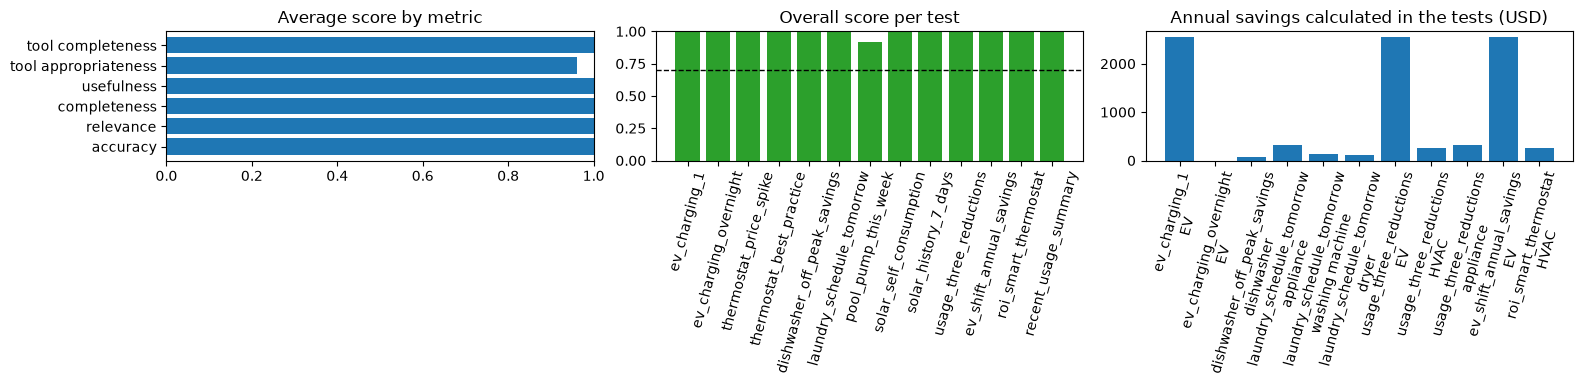

In [20]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
avg = report["metric_averages"]
axes[0].barh([m.replace("_", " ") for m in avg], list(avg.values()))
axes[0].set_xlim(0, 1); axes[0].set_title("Average score by metric")
per = pd.DataFrame(report["per_test"])
axes[1].bar(per["test_id"], per["overall"].fillna(0), color=["tab:green" if p else "tab:red" for p in per["passed"]])
axes[1].axhline(PASS_THRESHOLD, color="black", linestyle="--", linewidth=1)
axes[1].set_ylim(0, 1); axes[1].set_title("Overall score per test"); axes[1].tick_params(axis="x", rotation=75)

savings = []
for r in test_results:
    for m in (r["response"]["messages"] if isinstance(r.get("response"), dict) else []):
        if isinstance(m, ToolMessage) and m.name == "calculate_energy_savings":
            try:
                data = json.loads(m.content)
            except (TypeError, ValueError):
                continue
            if "annual_savings_usd" in data:
                savings.append((f"{r['test_id']}\n{data['device_type']}", data["annual_savings_usd"]))
if savings:
    axes[2].bar([s[0] for s in savings], [s[1] for s in savings])
    axes[2].set_title("Annual savings calculated in the tests (USD)"); axes[2].tick_params(axis="x", rotation=75)
else:
    axes[2].text(0.5, 0.5, "No savings calculations in this run", ha="center"); axes[2].set_axis_off()
plt.tight_layout(); plt.show()

## 7. Required tool calls

Scores are averages; a skipped data step is not a matter of degree. This cell checks, for every test, that each expected tool was called and returned data, and stops the notebook if any did not.

In [21]:
required = pd.DataFrame([{"test_id": e["test_id"], "expected": ", ".join(r["expected_tools"]),
                          "missing": ", ".join(e["tool_eval"]["missing_tools"]) or "-",
                          "called but returned no data": ", ".join(e["tool_eval"]["failed_required_tools"]) or "-",
                          "results not reflected in answer": ", ".join(e["tool_eval"]["unused_tools"]) or "-",
                          "agent validation retries": r["validation"]["retries"]}
                         for e, r in zip(report["evaluations"], test_results)])
display(required)
failures = [e["test_id"] for e in report["evaluations"] if not e["required_calls_ok"]]
assert not failures, f"required tool calls missing in: {failures}"
print(f"All {len(required)} tests called every expected tool, and each returned data.")

,test_id,expected,missing,called but returned no data,results not reflected in answer,agent validation retries
0,ev_charging_1,"get_weather_forecast, get_electricity_prices",-,-,-,1
1,ev_charging_overnight,get_electricity_prices,-,-,-,2
2,thermostat_price_spike,"get_electricity_prices, get_weather_forecast",-,-,-,0
3,thermostat_best_practice,search_energy_tips,-,-,-,0
4,dishwasher_off_peak_savings,"get_electricity_prices, calculate_energy_savings",-,-,-,0
5,laundry_schedule_tomorrow,get_electricity_prices,-,-,-,2
6,pool_pump_this_week,get_weather_forecast,-,-,-,0
7,solar_self_consumption,"get_weather_forecast, query_solar_generation",-,-,-,2
8,solar_history_7_days,query_solar_generation,-,-,-,0
9,usage_three_reductions,"query_energy_usage, search_energy_tips, get_electricity_prices, ca...",-,-,-,2


All 13 tests called every expected tool, and each returned data.
